In [2]:
!pip install neurokit2 py-ecg-detectors


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [8]:
%pip install hrv-analysis

  Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl.metadata (61 kB)
Using cached scipy-1.18.1-cp313-cp313-win_amd64.whl (36.6 MB)
  Attempting uninstall: scipy
    Found existing installation: scipy 1.16.2
    Uninstalling scipy-1.16.2:
      Successfully uninstalled scipy-1.16.2
Note: you may need to restart the kernel to use updated packages.


  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
neurokit2 0.2.13 requires pandas<3.0.0, but you have pandas 3.1.0 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
%pip install --upgrade --force-reinstall matplotlib matplotlib-inline

  Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl.metadata (80 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
Using cached matplotlib-3.11.2-cp313-cp313-win_amd64.whl (9.3 MB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.5 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.5 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.5 MB 529.2 kB/s eta 0:00:04
   -------- ------------------------------- 0.5/2.5 MB 529.2 kB/s eta 0:00:04
   -------- ------------------------------- 0.5/2.5 MB 529.2 kB/s eta 0:00:04
   ------------ --------------------------- 0.8/2.5 MB 510.2 kB/s eta 0:00:04
   ------------ ---

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
neurokit2 0.2.13 requires pandas<3.0.0, but you have pandas 3.1.0 which is incompatible.
streamlit 1.57.0 requires pillow<13,>=7.1.0, but you have pillow 13.0.0 which is incompatible.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


=== 1. COMPARACIÓN DE DETECCIÓN DE PICOS R ===
Total picos R con NeuroKit2:            53
Total picos R con Detectors (Pan-Tomp): 54

=== 2 y 3. TABLA COMPARATIVA DE CARACTERÍSTICAS HRV (hrvanalysis) ===
           NeuroKit2  Detectors (Pan-Tompkins)
mean_nni  942.692308                930.188679
sdnn       61.168856                109.553123
rmssd      62.763171                121.029240
pnni_50    15.686275                 50.000000
nni_50      8.000000                 26.000000


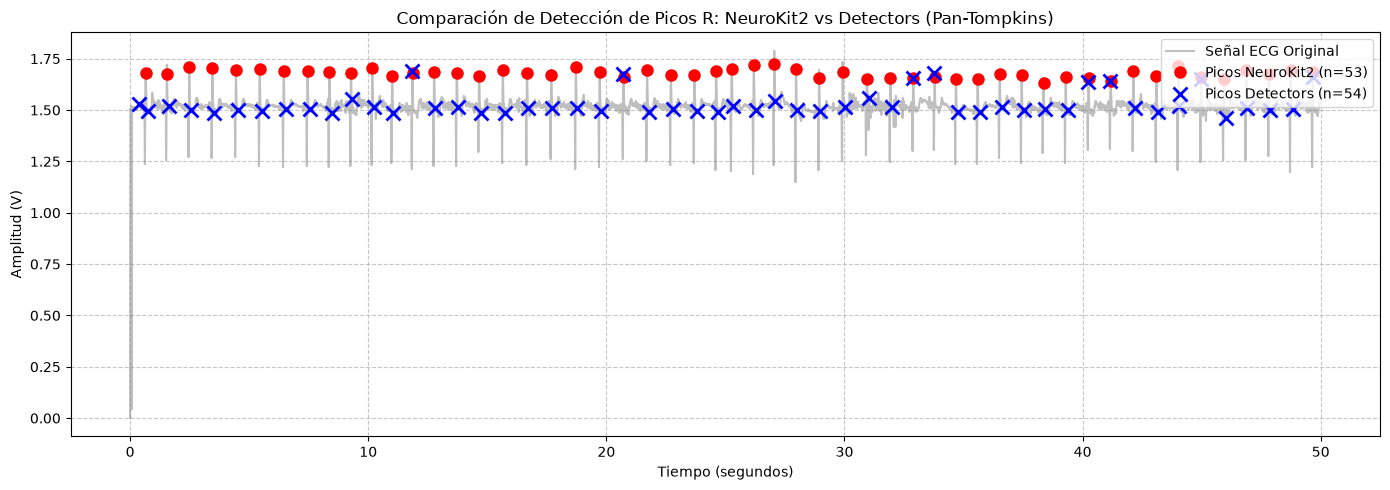

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import neurokit2 as nk
import numpy as np
import pandas as pd
from ecgdetectors import Detectors
from hrvanalysis import get_time_domain_features

# 1. Cargar señal y definir parámetros
signal = np.loadtxt("datosECG1.txt")
fs = 100  # Frecuencia de muestreo (Hz)
time = np.arange(len(signal)) / fs

# =============================================================================
# PUNTO 1: DETECCIÓN Y COMPARACIÓN DE PICOS R (NeuroKit2 vs Detectors)
# =============================================================================

# A) Limpieza previa con NeuroKit2 (evita romper por compatibilidad de Pandas)
cleaned_signal = nk.ecg_clean(signal, sampling_rate=fs, method="neurokit")

# Método A: Detección de picos R con NeuroKit2
_, r_peaks_nk_dict = nk.ecg_peaks(
    cleaned_signal, sampling_rate=fs, method="neurokit"
)
r_peaks_nk = r_peaks_nk_dict["ECG_R_Peaks"]

# Método B: Detección de picos R con la librería Detectors (Pan-Tompkins)
detectors = Detectors(fs)
r_peaks_detectors = np.array(detectors.pan_tompkins_detector(signal))

print("=== 1. COMPARACIÓN DE DETECCIÓN DE PICOS R ===")
print(f"Total picos R con NeuroKit2:            {len(r_peaks_nk)}")
print(f"Total picos R con Detectors (Pan-Tomp): {len(r_peaks_detectors)}")

# =============================================================================
# PUNTOS 2 y 3: CÁLCULO DE HRV CON HRVANALYSIS
# =============================================================================

# Convertir índices a intervalos R-R en milisegundos (ms)
rr_nk_ms = np.diff(r_peaks_nk) * (1000 / fs)
rr_det_ms = np.diff(r_peaks_detectors) * (1000 / fs)

# Extracción de características en el dominio del tiempo usando hrvanalysis
hrv_nk = get_time_domain_features(rr_nk_ms)
hrv_det = get_time_domain_features(rr_det_ms)

# Crear DataFrame comparativo
df_hrv_compare = pd.DataFrame(
    [hrv_nk, hrv_det], index=["NeuroKit2", "Detectors (Pan-Tompkins)"]
)

print(
    "\n=== 2 y 3. TABLA COMPARATIVA DE CARACTERÍSTICAS HRV (hrvanalysis) ==="
)
print(df_hrv_compare[["mean_nni", "sdnn", "rmssd", "pnni_50", "nni_50"]].T)

# =============================================================================
# VISUALIZACIÓN COMPARATIVA EN GRÁFICA
# =============================================================================
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(time, signal, label="Señal ECG Original", color="gray", alpha=0.5)

# Picos de NeuroKit2
ax.plot(
    r_peaks_nk / fs,
    signal[r_peaks_nk],
    "ro",
    markersize=8,
    label=f"Picos NeuroKit2 (n={len(r_peaks_nk)})",
)

# Picos de Detectors
ax.plot(
    r_peaks_detectors / fs,
    signal[r_peaks_detectors],
    "bx",
    markersize=10,
    mew=2,
    label=f"Picos Detectors (n={len(r_peaks_detectors)})",
)

ax.set_title(
    "Comparación de Detección de Picos R: NeuroKit2 vs Detectors (Pan-Tompkins)"
)
ax.set_xlabel("Tiempo (segundos)")
ax.set_ylabel("Amplitud (V)")
ax.grid(True, linestyle="--", alpha=0.7)
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()